In [1]:
# pip install scikit-learn glances nvidia-ml-py pandas matplotlib torchmetrics torchinfo albumentations tensorboard kaggle

In [2]:
import torch
from torch import nn
from torchinfo import summary
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.optim.lr_scheduler import ReduceLROnPlateau
import matplotlib.pyplot as plt

from going_modular.custom_data_setup_main_train import LoadDataset
from going_modular import engine, utils
from going_modular import custom_data_setup_pre_train
from going_modular.OneHeadModel import OneHeadModel
import helper_functions

In [3]:
allow_train = True
EPOCHS = 10
BATCH_SIZE = 128
shrink_size = None

crop_size = 240

num_augs = 0
p_dropout = 0.4
lr = 1e-3
weight_deacay = 1e-5
T_max = 10
eta_min = 1e-5
momentum = 0.9

freeze_encoder = False

In [4]:
# Set matmul precision for TF32 usage on Ampere+ GPUs
# torch.set_float32_matmul_precision('medium')

# Setup device agnostic code
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

Augmentation

In [5]:
train_transforms = helper_functions.get_augmentation_train_transforms(num_augs, crop_size)
test_transforms = helper_functions.get_augmentation_test_transforms(crop_size)
no_transforms = helper_functions.get_augmentation_no_transforms(crop_size)

In [6]:
# load all dataloaders

train_dataloader, class_names = custom_data_setup_pre_train.create_train_dataloader(
    transform=train_transforms, 
    batch_size=BATCH_SIZE,
    shrink_size=shrink_size) 

train_exp_dataloader, class_names = custom_data_setup_pre_train.create_train_dataloader(
    transform=test_transforms,
    batch_size=BATCH_SIZE,
    shrink_size=shrink_size) 

val_dataloader, class_names = custom_data_setup_pre_train.create_test_dataloader(
    transform=test_transforms, 
    batch_size=BATCH_SIZE,
    shrink_size=shrink_size) 

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.117904..2.2489083].


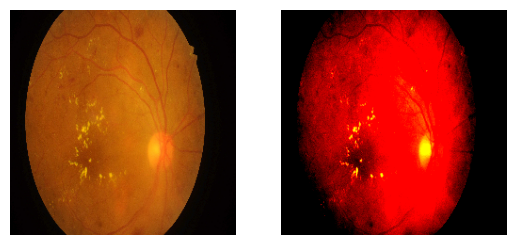

In [7]:
# plot some of the images to check applied augmentations

IDRID_image_folder = "../IDRID/Imagenes/Imagenes" 
IDRID_csv_file = "../IDRID/idrid_labels.csv"

test_dataset_with_transform = LoadDataset(IDRID_image_folder, IDRID_csv_file, transform=train_transforms)
test_dataset_no_transform = LoadDataset(IDRID_image_folder, IDRID_csv_file, transform=no_transforms)

for i in range(1):
    img_2 = test_dataset_with_transform[i][0].permute(1, 2, 0)
    img_1 = test_dataset_no_transform[i][0].permute(1, 2, 0)
    fig, axes = plt.subplots(1, 2)
    axes[0].imshow(img_1.numpy())
    axes[1].imshow(img_2.numpy())
    axes[0].axis(False)
    axes[1].axis(False)
    plt.show()

In [8]:
model = OneHeadModel(device=device, p_dropout=p_dropout).to(device)

In [9]:
# Freeze all base layers in the "features" section of the model (the feature extractor) by setting requires_grad=False
if freeze_encoder:
    for param in model.encoder.parameters():
        param.requires_grad = False

In [10]:
# Print a summary using torchinfo (uncomment for actual output)
torch.manual_seed(33)
summary(
model=model, 
input_size=(32, 3, crop_size, crop_size), # make sure this is "input_size", not "input_shape"
col_names=["input_size", "output_size", "num_params", "trainable"],
col_width=20,
row_settings=["var_names"]) 

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
OneHeadModel (OneHeadModel)                                  [32, 3, 240, 240]    [32]                 --                   True
├─Sequential (encoder)                                       [32, 3, 240, 240]    [32, 1280, 8, 8]     --                   True
│    └─Conv2dNormActivation (0)                              [32, 3, 240, 240]    [32, 32, 120, 120]   --                   True
│    │    └─Conv2d (0)                                       [32, 3, 240, 240]    [32, 32, 120, 120]   864                  True
│    │    └─BatchNorm2d (1)                                  [32, 32, 120, 120]   [32, 32, 120, 120]   64                   True
│    │    └─SiLU (2)                                         [32, 32, 120, 120]   [32, 32, 120, 120]   --                   --
│    └─Sequential (1)                                        [32, 32, 120, 120]   [32, 16, 120

In [11]:
# Define loss and optimizer

loss_fn_classification = nn.BCEWithLogitsLoss().to(device)

optimizer = torch.optim.SGD(model.parameters(), lr=lr, weight_decay=weight_deacay, momentum=momentum, nesterov=True)
scheduler = CosineAnnealingLR(optimizer, T_max=T_max, eta_min=eta_min)

# scheduler = ReduceLROnPlateau(optimizer, 'min', patience=3, min_lr=1e-6)

In [12]:
# model = torch.compile(model)

train_results = []

if allow_train:
    # Set the random seeds
    torch.manual_seed(1404)
    torch.cuda.manual_seed(1404)

    # Start the timer
    from timeit import default_timer as timer 
    start_time = timer()

    # Setup training and save the results
    train_results, val_results = engine.train(
        model=model,
        train_dataloader=train_dataloader,
        val_dataloader=val_dataloader,
        optimizer=optimizer,
        scheduler=scheduler,
        loss_fn_classification=loss_fn_classification,
        epochs=EPOCHS,
        device=device)
        
    # End the timer and print out how long it took
    end_time = timer()
    print(f"[INFO] Total training time: {end_time-start_time:.3f} seconds")

    utils.save_model(model=model, target_dir='models', model_name='pre_train_model.pth')
else:
    model.load_state_dict(torch.load('models/pre_train_model.pth', weights_only=True, map_location=device))

  0%|          | 0/10 [00:00<?, ?it/s]


Epoch 1, Learning Rate: 0.0009757729755661011
loss_classification_train: 0.5834 | loss_classification_val: 0.5990 | acc_classification_val: 0.6843

Epoch 2, Learning Rate: 0.000905463412215599
loss_classification_train: 0.5376 | loss_classification_val: 0.4911 | acc_classification_val: 0.7944

Epoch 3, Learning Rate: 0.0007959536998847742
loss_classification_train: 0.5212 | loss_classification_val: 0.4426 | acc_classification_val: 0.8236

Epoch 4, Learning Rate: 0.000657963412215599
loss_classification_train: 0.5073 | loss_classification_val: 0.4081 | acc_classification_val: 0.8545

Epoch 5, Learning Rate: 0.000505
loss_classification_train: 0.4988 | loss_classification_val: 0.3809 | acc_classification_val: 0.8545

Epoch 6, Learning Rate: 0.0003520365877844011
loss_classification_train: 0.4898 | loss_classification_val: 0.3608 | acc_classification_val: 0.8667

Epoch 7, Learning Rate: 0.00021404630011522585
loss_classification_train: 0.4848 | loss_classification_val: 0.3476 | acc_class

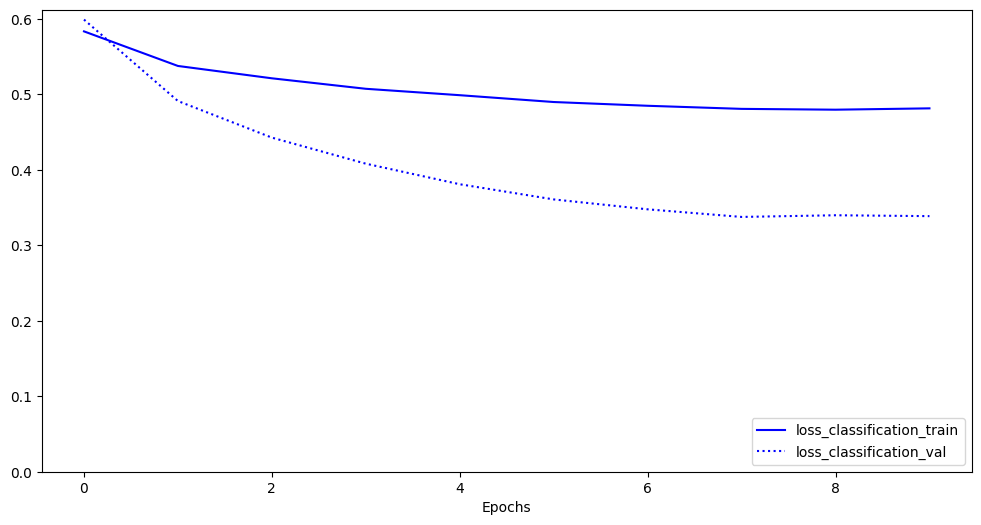

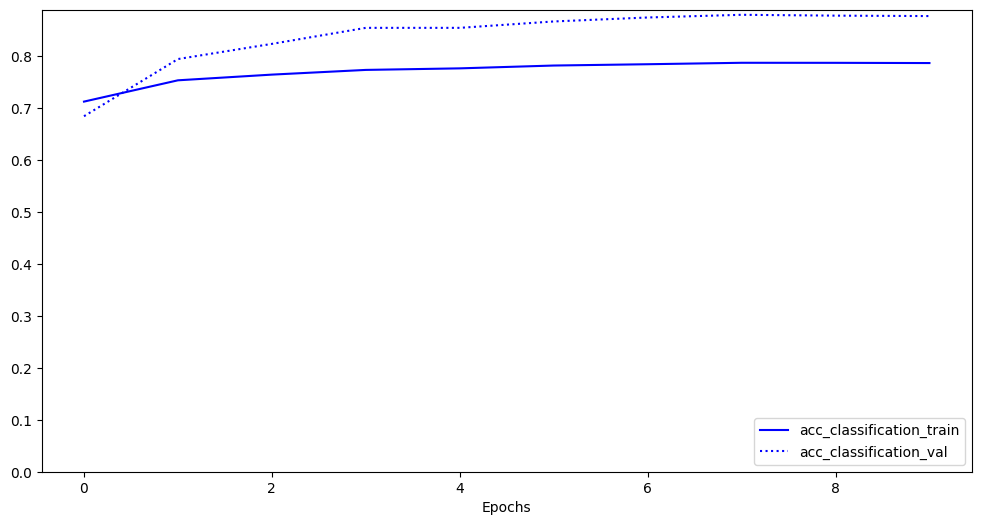

In [13]:
if allow_train:
    helper_functions.plot_loss_curves(train_results, val_results)
    helper_functions.plot_acc_curves(train_results, val_results)

per class precision: [0.8534168  0.90315186]
per class recall: [0.90637119 0.84868067]
per class f1_score: [0.87909726 0.87506941]
average scores >>> precision: 0.8782843297714762 | recall: 0.8775259294397033 | f1_score: 0.877083332711751
accuracy: 0.8771163298743856
QWK:  0.7543964657175979


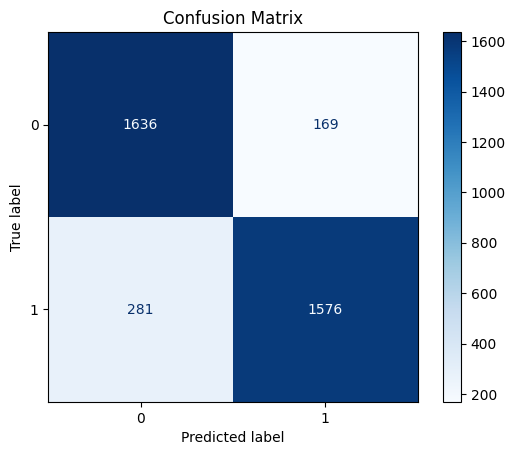

In [14]:
# results is for APTOS-2019

test_results = engine.test_step(
    model=model,
    dataloader=val_dataloader,
    device=device)

per class precision: [0.81614695 0.7294769 ]
per class recall: [0.9450988  0.41015457]
per class f1_score: [0.87590219 0.52507902]
average scores >>> precision: 0.7728119240940647 | recall: 0.6776266858465827 | f1_score: 0.7004906014355584
accuracy: 0.8032226840516996
QWK:  0.41302306111769804


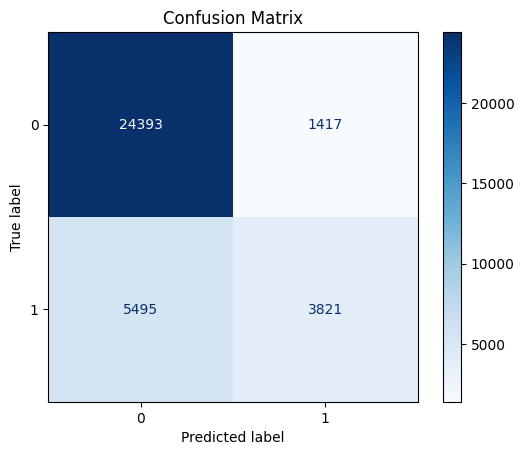

In [15]:
# results is for APTOS-2015

test_results = engine.test_step(
    model=model,
    dataloader=train_exp_dataloader,
    device=device)

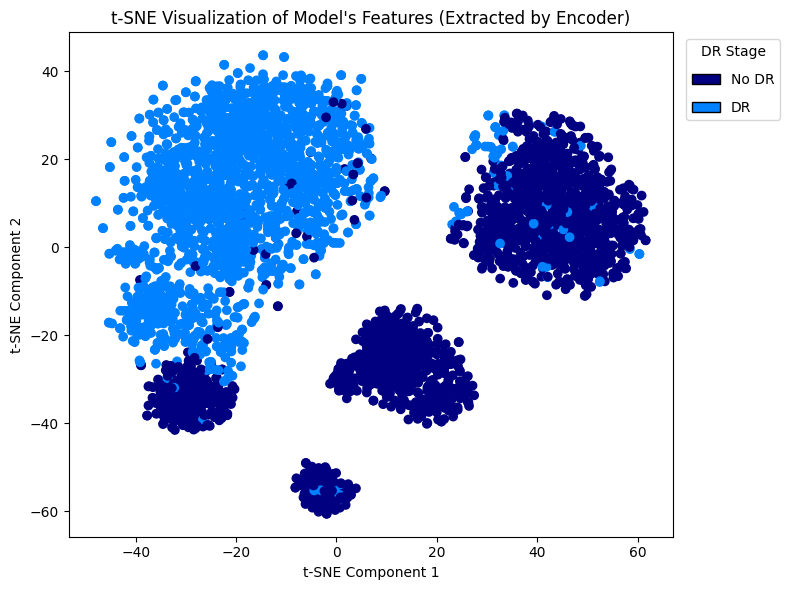

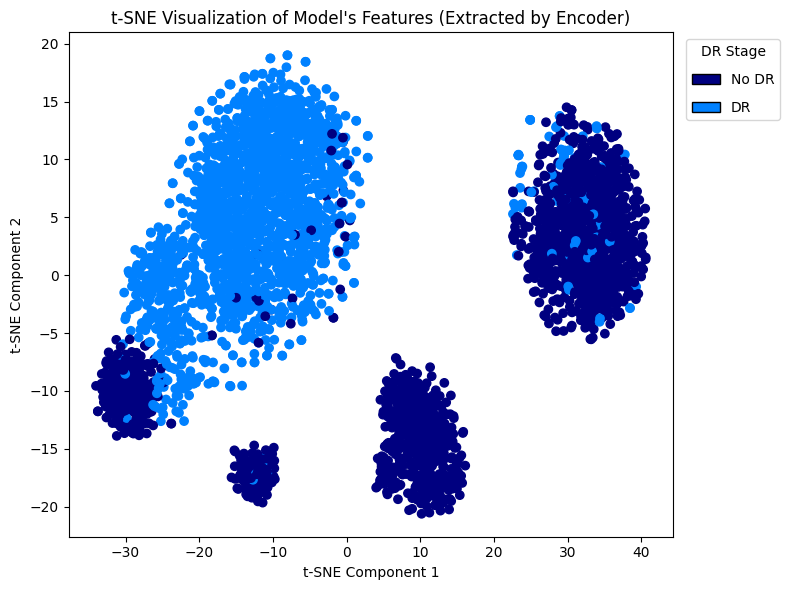

In [17]:
helper_functions.plot_t_SNE(model=model,
                        dataloader=val_dataloader,
                        perp_vals=[30, 100],
                        NUM_ITER=2000)